# Audio Feature Extraction: Mel Spectrogram, RMS Energy and Spectral Centroid

In [ ]:
!pip install librosa matplotlib numpy

import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
from IPython.display import Audio

## STEP 1: Loading the audio file

In [ ]:
audio_path = "/content/utvekam-from-utvekam-2026-remastered.mp3"
y, sr = librosa.load(audio_path, sr=None)

print(f"Sampling rate : {sr} Hz")
print(f"Samples       : {len(y)}")
print(f"Duration      : {len(y) / sr:.2f} s")

Audio(y, rate=sr)

Sampling rate : 48000 Hz
Samples       : 7572096
Duration      : 157.75 s


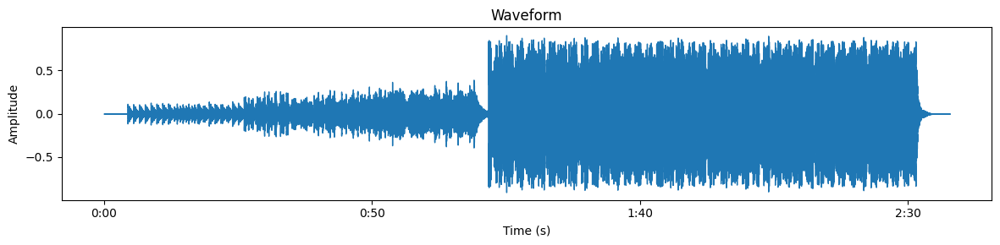

In [ ]:
plt.figure(figsize=(12, 3))
librosa.display.waveshow(y, sr=sr)
plt.title("Waveform")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

## 2. Mel spectrogram

In [ ]:
n_fft = 2048
hop_length = 512
n_mels = 128

mel_spec = librosa.feature.melspectrogram(
    y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels
)
mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

print("Mel spectrogram shape:", mel_spec_db.shape)

Mel spectrogram shape: (128, 14790)


## 3. RMS energy and spectral centroid

In [ ]:
rms = librosa.feature.rms(y=y, frame_length=n_fft, hop_length=hop_length)[0]

centroid = librosa.feature.spectral_centroid(
    y=y, sr=sr, n_fft=n_fft, hop_length=hop_length
)[0]

times = librosa.frames_to_time(np.arange(len(rms)), sr=sr, hop_length=hop_length)

print(f"Mean RMS energy       : {rms.mean():.4f}")
print(f"Mean spectral centroid: {centroid.mean():.2f} Hz")

Mean RMS energy       : 0.1305
Mean spectral centroid: 2026.04 Hz


## 4. Visualization

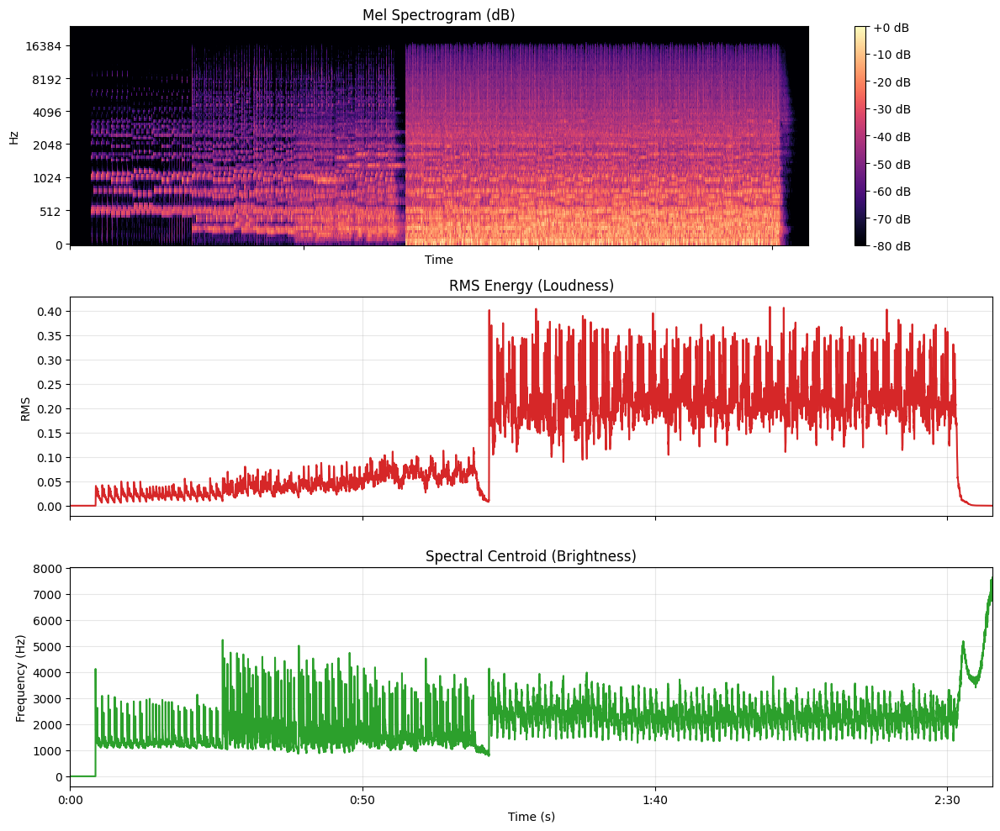

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

img = librosa.display.specshow(
    mel_spec_db, sr=sr, hop_length=hop_length,
    x_axis="time", y_axis="mel", ax=axes[0]
)
axes[0].set_title("Mel Spectrogram (dB)")
fig.colorbar(img, ax=axes[0], format="%+2.0f dB")

axes[1].plot(times, rms, color="tab:red")
axes[1].set_title("RMS Energy (Loudness)")
axes[1].set_ylabel("RMS")
axes[1].grid(alpha=0.3)

axes[2].plot(times, centroid, color="tab:green")
axes[2].set_title("Spectral Centroid (Brightness)")
axes[2].set_ylabel("Frequency (Hz)")
axes[2].set_xlabel("Time (s)")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

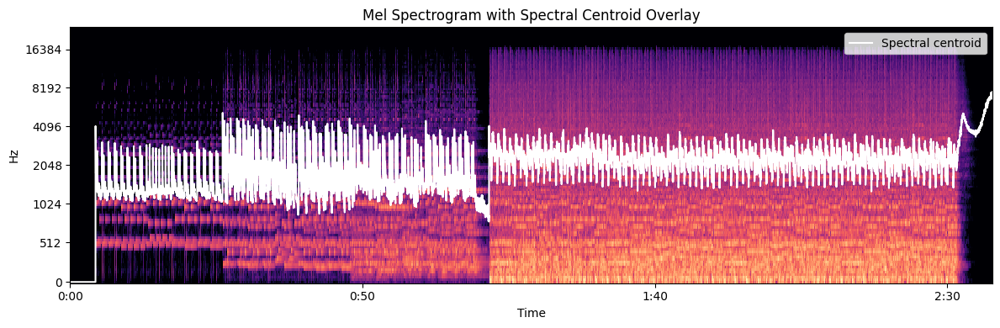

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4))
librosa.display.specshow(
    mel_spec_db, sr=sr, hop_length=hop_length,
    x_axis="time", y_axis="mel", ax=ax
)
ax.set_title("Mel Spectrogram with Spectral Centroid Overlay")
ax.plot(times, centroid, color="white", linewidth=1.5, label="Spectral centroid")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()